# 3 · Reading physics in an anomaly

Physics residuals, the gradient-boosting classifier, and a tiny run of the sequence model.
See [Lesson 3](../docs/lessons/03-reading-physics-in-an-anomaly.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fdicps import plotting
from fdicps.dual_anomaly_data_generation.parameters import load_sensor_parameters

plotting.use_style()
P = load_sensor_parameters()

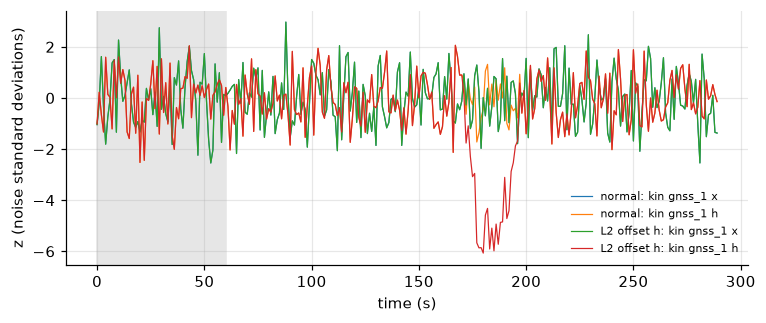

In [2]:
from fdicps.dual_anomaly_data_generation.scenarios import make_scenario
from fdicps.physical_vs_fdi_classification.residuals import REFERENCE, kinematic_family, window_z

fig, ax = plt.subplots(figsize=(8, 3))
for label, level in (("normal", None), ("fdi", 2)):
    s = make_scenario(1_000_007, label, level=level)
    for name, terms in kinematic_family(s.values[None], P).items():
        if name.startswith("kin gnss_1"):
            z = window_z(terms, 10)[0]
            ax.plot(z, lw=0.8, label=f"{s.subtype}: {name}")
ax.axvspan(0, REFERENCE, color="0.9")
ax.set(xlabel="time (s)", ylabel="z (noise standard deviations)")
ax.legend(fontsize=7, frameon=False);

In [3]:
from sklearn.metrics import confusion_matrix

from fdicps.dual_anomaly_data_generation.scenarios import generate_dataset
from fdicps.physical_vs_fdi_classification.classifier import PhysicsClassifier

train, test = generate_dataset(range(900)), generate_dataset(range(20_000, 20_300))
clf = PhysicsClassifier(max_iter=150).fit(train.values, train.label, P)
pred = clf.predict(test.values, P)
print(confusion_matrix(test.label, pred))
for k in range(4):
    sel = (test.label == 2) & (test.level == k)
    print(f"L{k}: called FDI {np.mean(pred[sel] == 2):.2f}")

[[96  0  4]
 [ 2 96  2]
 [23  3 74]]
L0: called FDI 1.00
L1: called FDI 0.96
L2: called FDI 0.92
L3: called FDI 0.08


In [4]:
from fdicps.physical_vs_fdi_classification.sequence_model import SequenceClassifier

cnn = SequenceClassifier(epochs=3).fit(train.values[:300], train.label[:300], P)
print("training loss by epoch:", [round(x, 3) for x in cnn.loss_history])
print("accuracy on the 300 test scenarios:", np.mean(cnn.predict(test.values, P) == test.label).round(3))

training loss by epoch: [1.082, 0.992, 0.888]
accuracy on the 300 test scenarios: 0.463
